# Embedding maps: checks

`notebooks/embedding_maps.ipynb` draws nine film spaces four ways (PCA, Isomap, t-SNE, UMAP). This notebook checks
what those maps and spaces can be trusted for. It reads the maps that notebook saves to
`data/raw/features/embedding_maps.csv`, so run that one first.

| Section | Question |
|---|---|
| 1. Stability | Do the t-SNE and UMAP maps stay the same under another seed or setting? |
| 2. Do the spaces agree? | Are a film's nearest films the same in two different spaces? |
| 3. Clusters | Cut each full space into 10 groups. Does profit differ between them more than chance? |
| 4. Release year | Do the spaces sort films by when they were made? |
| 5. Neighbours by hand | A blind sheet for judging nearest films by hand, and the cell that scores it |
| 6. What the checks show | The numbers behind the takeaway |

**Takeaway.** Only the tag spaces' islands come back reliably when t-SNE or UMAP is redrawn. Islands on the text,
cast and arc maps change with the seed, so they shouldn't be described as groups. The spaces mostly disagree about
which films are alike. The closest pair is two descriptions of the same story (MovieSum summaries and Wikipedia
plots), and sentiment arcs agree with nothing. Cut into 10 clusters, only the tag spaces, genre shares and cast and
crew separate profit beyond chance once budget, year and genre are taken out, and even the best explains 5.5%. Tags,
cast and crew and reviews sort films strongly by release year. The hand-check sheet is written but not judged yet.
Section 6 has the numbers.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score

sys.path.insert(0, "..")
from analysis.film_spaces import FEATURES as F, SEED, load_spaces, reception_mask, sample
from analysis.projections import knn, umap

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
OUT = Path("../analysis/embedding_maps")
OUT.mkdir(exist_ok=True)

d = sample()
S = load_spaces(d)
maps = pd.read_csv(F / "embedding_maps.csv", dtype={"tconst": str})
NAMES = list(S)
assert set(maps.space) == set(NAMES), set(NAMES) ^ set(maps.space)

def saved_map(name, method):
    m = maps[(maps.space == name) & (maps.method == method)].set_index("tconst").loc[S[name][0]]
    return m[["x", "y"]].to_numpy()

def reduced(V, seed=SEED):
    """The input t-SNE and UMAP get in the main notebook: the first 50 principal components."""
    return PCA(min(50, V.shape[1]), random_state=seed).fit_transform(V)

def overlap(a, b):
    """Mean share of each film's neighbours in a that are also its neighbours in b."""
    return float(np.mean([len(set(x) & set(y)) / len(x) for x, y in zip(a, b)]))
print(f"{len(maps):,} map rows for {maps.space.nunique()} spaces")

143,336 map rows for 9 spaces


## 1. Stability: another seed, another setting

t-SNE and UMAP start from a random layout and settle on one of many good-enough ones. If a cluster on a map is real,
it should come back when the seed changes. Each space's t-SNE and UMAP maps are redrawn with seeds 2 and 3, and with
a smaller and a larger neighbourhood (t-SNE perplexity 10 and 100 against 30; UMAP n_neighbors 5 and 50 against 15).
Each redraw is compared with the saved seed-1 map on two things:

t-SNE started from the PCA layout (as in the main notebook) gives the same map whatever the seed, because the seed
only sets a random starting layout. Its seed redraws therefore start from a random layout, which is the harder test.

- **same neighbours**: the share of each film's 10 nearest films on the seed-1 map that are also its 10 nearest on
  the redraw.
- **same islands**: HDBSCAN finds the islands on each map (groups of at least 1% of the films, and at least 15).
  The adjusted Rand index compares the two groupings: 1 is the same islands, 0 is no more alike than chance.

In [2]:
def islands(Y):
    return HDBSCAN(min_cluster_size=max(15, len(Y) // 100), copy=True).fit_predict(Y)

def redraw(method, Z, seed, setting, init="pca"):
    if method == "t-SNE":
        return TSNE(2, perplexity=setting, init=init, random_state=seed).fit_transform(Z)
    return umap.UMAP(n_neighbors=setting, min_dist=0.1, random_state=seed, n_jobs=1,
                     compatibility_layout=True).fit_transform(Z)

# t-SNE started from the PCA layout, as in the main notebook, gives the same map for every seed: the seed only
# sets a random starting layout. So its seed redraws start from random layouts instead.
RUNS = {"t-SNE": [("seed 2", 2, 30, "random"), ("seed 3", 3, 30, "random"), ("perplexity 10", 1, 10, "pca"),
                  ("perplexity 100", 1, 100, "pca")],
        "UMAP": [("seed 2", 2, 15, None), ("seed 3", 3, 15, None), ("n_neighbors 5", 1, 5, None),
                 ("n_neighbors 50", 1, 50, None)]}
rows = []
for name in NAMES:
    ids, V = S[name]
    Z = reduced(V)
    for method, runs in RUNS.items():
        Y0 = saved_map(name, method)
        n0, c0 = knn(Y0), islands(Y0)
        for label, seed, setting, init in runs:
            Y = redraw(method, Z, seed, setting, init or "pca")
            c = islands(Y)
            rows.append({"space": name, "method": method, "redraw": label, "same neighbours": overlap(n0, knn(Y)),
                         "same islands": adjusted_rand_score(c0, c), "islands seed 1": int(c0.max() + 1),
                         "islands redraw": int(c.max() + 1)})
stab = pd.DataFrame(rows)
stab.to_csv(OUT / "stability.csv", index=False)
print(stab.round(3).to_string(index=False))
print()
print(stab.assign(kind=np.where(stab.redraw.str.startswith("seed"), "other seed", "other setting"))
      .pivot_table(index="space", columns=["method", "kind"], values=["same neighbours", "same islands"])
      .loc[NAMES].round(2).to_string())

                 space method         redraw  same neighbours  same islands  islands seed 1  islands redraw
           Screenplays  t-SNE         seed 2            0.602         0.389              12               8
           Screenplays  t-SNE         seed 3            0.629        -0.076              12               3
           Screenplays  t-SNE  perplexity 10            0.561         0.377              12              13
           Screenplays  t-SNE perplexity 100            0.481         0.061              12               6
           Screenplays   UMAP         seed 2            0.555         0.441               2               2
           Screenplays   UMAP         seed 3            0.592         0.740               2               3
           Screenplays   UMAP  n_neighbors 5            0.384         0.349               2               5
           Screenplays   UMAP n_neighbors 50            0.450        -0.038               2              12
    MovieSum summaries  t-SN

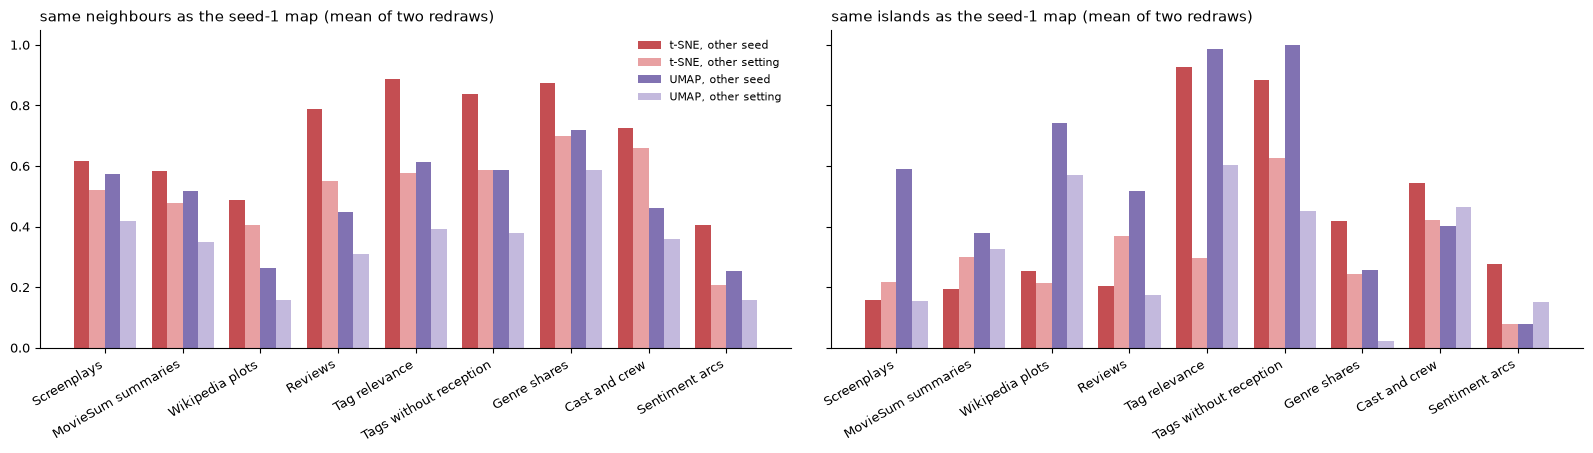

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), sharey=True)
kinds = {"other seed": stab.redraw.str.startswith("seed"), "other setting": ~stab.redraw.str.startswith("seed")}
x = np.arange(len(NAMES))
for ax, col in zip(axes, ["same neighbours", "same islands"]):
    for i, (method, kind) in enumerate([(m, k) for m in RUNS for k in kinds]):
        r = stab[(stab.method == method) & kinds[kind]].groupby("space")[col].mean().loc[NAMES]
        ax.bar(x + (i - 1.5) * 0.2, r, 0.2, label=f"{method}, {kind}",
               color=["#c44e52", "#e8a0a2", "#8172b2", "#c3b9dd"][i])
    ax.set_xticks(x, NAMES, rotation=30, ha="right"); ax.set_title(f"{col} as the seed-1 map (mean of two redraws)", loc="left")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 2. Do the spaces agree on which films are alike?

For each pair of spaces, on the films both cover, the share of each film's 10 nearest films in one space that are
also among its 10 nearest in the other. Neighbours are found in the full spaces, not on maps. Chance is about
10 / number of shared films, given under each value. Tag relevance and tags without reception share 978 of their
1,084 columns, so that pair is close to 1 by construction.

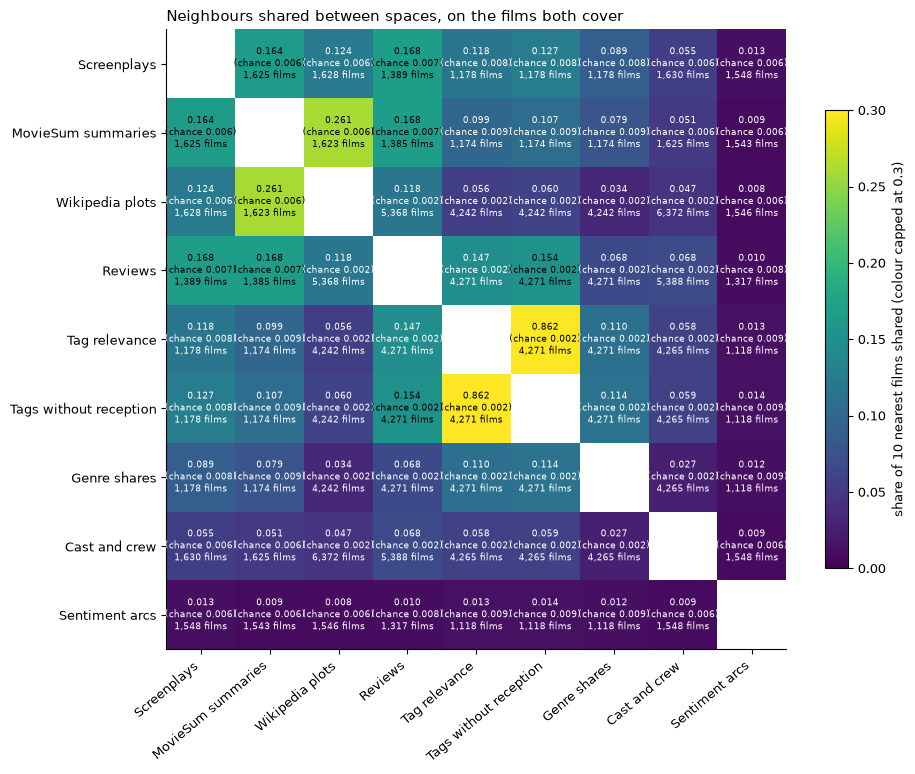

                        Screenplays  MovieSum summaries  Wikipedia plots  Reviews  Tag relevance  Tags without reception  Genre shares  Cast and crew  Sentiment arcs
Screenplays                     NaN               0.164            0.124    0.168          0.118                   0.127         0.089          0.055           0.013
MovieSum summaries            0.164                 NaN            0.261    0.168          0.099                   0.107         0.079          0.051           0.009
Wikipedia plots               0.124               0.261              NaN    0.118          0.056                   0.060         0.034          0.047           0.008
Reviews                       0.168               0.168            0.118      NaN          0.147                   0.154         0.068          0.068           0.010
Tag relevance                 0.118               0.099            0.056    0.147            NaN                   0.862         0.110          0.058           0.013
Tags

In [4]:
A = pd.DataFrame(np.nan, NAMES, NAMES)
N = pd.DataFrame(0, NAMES, NAMES)
for i, a in enumerate(NAMES):
    for b in NAMES[i + 1:]:
        ia, Va = S[a]; ib, Vb = S[b]
        common = np.intersect1d(ia, ib)
        if len(common) < 100:
            continue
        pa = pd.Series(np.arange(len(ia)), ia).loc[common].to_numpy()
        pb = pd.Series(np.arange(len(ib)), ib).loc[common].to_numpy()
        A.loc[a, b] = A.loc[b, a] = overlap(knn(Va[pa]), knn(Vb[pb]))
        N.loc[a, b] = N.loc[b, a] = len(common)
A.to_csv(OUT / "space_agreement.csv")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(A, cmap="viridis", vmin=0, vmax=0.3)
for i in range(len(NAMES)):
    for j in range(len(NAMES)):
        if i != j and N.iat[i, j]:
            ax.text(j, i, f"{A.iat[i, j]:.3f}\n(chance {10 / (N.iat[i, j] - 1):.3f})\n{N.iat[i, j]:,} films",
                    ha="center", va="center", fontsize=6.5, color="white" if A.iat[i, j] < 0.15 else "black")
ax.set_xticks(range(len(NAMES)), NAMES, rotation=40, ha="right"); ax.set_yticks(range(len(NAMES)), NAMES)
plt.colorbar(im, label="share of 10 nearest films shared (colour capped at 0.3)", shrink=0.7)
ax.set_title("Neighbours shared between spaces, on the films both cover", loc="left")
plt.show()
pd.set_option("display.width", 250)
print(A.round(3).to_string())

## 3. Clusters in the full space

Islands on a map aren't a test, because the map makes them. Here each full space (its first 50 principal components)
is cut into 10 groups with k-means, before looking at profit. The number 10 is our choice and the same for every
space. **Profit by cluster** is the share of the variation in ln(multiple) that the cluster labels explain (eta
squared), raw and net of budget, year and genre. With 10 groups some of it comes by chance, so the labels are
shuffled between films 200 times for a null. Each cluster is named by the 3 tags whose mean relevance in it is
highest above their mean over all tagged films, using tags without reception, on the cluster's films that have tags.

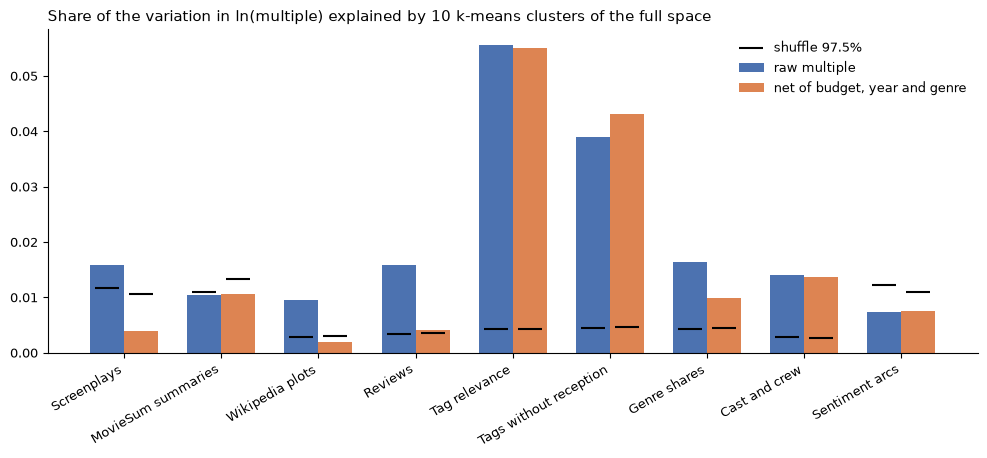

                 space  films  log_mult eta2  log_mult null 97.5%  log_mult_net eta2  log_mult_net null 97.5%
           Screenplays   1630          0.016                0.012              0.004                    0.011
    MovieSum summaries   1625          0.010                0.011              0.011                    0.013
       Wikipedia plots   6399          0.009                0.003              0.002                    0.003
               Reviews   5405          0.016                0.003              0.004                    0.004
         Tag relevance   4271          0.056                0.004              0.055                    0.004
Tags without reception   4271          0.039                0.004              0.043                    0.005
          Genre shares   4271          0.016                0.004              0.010                    0.005
         Cast and crew   6414          0.014                0.003              0.014                    0.003
        Se

In [5]:
def eta2(y, lab):
    m = pd.Series(y).groupby(lab).transform("mean").to_numpy()
    return float(((m - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum())

tag_ids = pd.read_csv(F / "tag_relevance_ids.csv", dtype={"tconst": str}).tconst
tags = pd.read_csv(F / "tag_relevance_tags.csv").tag
keep = ~reception_mask(tags)
T = pd.DataFrame(np.load(F / "tag_relevance.npy")[:, keep], index=tag_ids, columns=tags[keep])
T_mean = T.mean()

rng = np.random.default_rng(SEED)
cl_rows, desc = [], []
for name in NAMES:
    ids, V = S[name]
    lab = KMeans(10, n_init=10, random_state=SEED).fit_predict(reduced(V))
    f = d.loc[ids]
    row = {"space": name, "films": len(ids)}
    for col in ("log_mult", "log_mult_net"):
        y = f[col].to_numpy()
        null = [eta2(y, rng.permutation(lab)) for _ in range(200)]
        row[f"{col} eta2"] = eta2(y, lab)
        row[f"{col} null 97.5%"] = float(np.percentile(null, 97.5))
    cl_rows.append(row)
    for k in range(10):
        members = ids[lab == k]
        tagged = T.index.intersection(members)
        top = (T.loc[tagged].mean() - T_mean).nlargest(3).index if len(tagged) >= 20 else []
        g = f.primary_genre[lab == k]
        desc.append({"space": name, "cluster": k, "films": len(members),
                     "median multiple": float(np.exp(f.log_mult[lab == k].median())),
                     "median net": float(f.log_mult_net[lab == k].median()),
                     "main genre": f"{g.value_counts().index[0]} ({g.value_counts(normalize=True).iloc[0]:.0%})",
                     "top tags": ", ".join(top) if len(top) else "(too few tagged films)"})
clusters = pd.DataFrame(cl_rows)
cluster_desc = pd.DataFrame(desc)
clusters.to_csv(OUT / "clusters.csv", index=False)
cluster_desc.to_csv(OUT / "cluster_descriptions.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(NAMES))
for i, (col, c) in enumerate([("log_mult", "#4c72b0"), ("log_mult_net", "#dd8452")]):
    ax.bar(x + (i - 0.5) * 0.35, clusters[f"{col} eta2"], 0.35, color=c,
           label="raw multiple" if col == "log_mult" else "net of budget, year and genre")
    ax.scatter(x + (i - 0.5) * 0.35, clusters[f"{col} null 97.5%"], marker="_", s=300, color="black", zorder=3,
               label="shuffle 97.5%" if i == 0 else None)
ax.set_xticks(x, NAMES, rotation=30, ha="right")
ax.set_title("Share of the variation in ln(multiple) explained by 10 k-means clusters of the full space", loc="left")
ax.legend(frameon=False); plt.show()
print(clusters.round(3).to_string(index=False))

In [6]:
pd.set_option("display.max_colwidth", 70)
cluster_desc.sort_values(["space", "median multiple"], ascending=[True, False]).round(2)

,space,cluster,films,median multiple,median net,main genre,top tags
74,Cast and crew,4,1510,2.45,0.42,Adventure (23%),"big budget, pg-13, adventure"
76,Cast and crew,6,627,2.20,-0.12,Comedy (39%),"comedy, fun movie, girlie movie"
73,Cast and crew,3,498,2.19,0.26,Comedy (44%),"comedy, funny, hip hop"
72,Cast and crew,2,1074,2.14,0.28,Horror (35%),"based on a video game, horror, action"
78,Cast and crew,8,534,2.07,0.20,Comedy (57%),"comedy, funny, hilarious"
...,...,...,...,...,...,...,...
22,Wikipedia plots,2,635,2.03,0.16,Drama (43%),"relationships, romantic, love"
24,Wikipedia plots,4,655,1.98,0.09,Comedy (48%),"sports, underdog, comedy"
25,Wikipedia plots,5,438,1.95,0.15,Adventure (57%),"mythology, fantasy, magic"
29,Wikipedia plots,9,525,1.87,0.24,Thriller (33%),"conspiracy, action, action packed"


## 4. Release year

If a space puts films from the same years together, a pattern on its map can be about era (writing style, what
Wikipedia editors cover, what MovieLens users tagged) rather than the films. **Year smoothness** is the Spearman
correlation between a film's release year and the mean year of its 10 nearest films, in the full space and on each
saved map. Year enters the net multiple, so the net profit scores in the main notebook already allow for a smooth
trend in profit over the years.

                        full space    PCA  Isomap  t-SNE   UMAP
space                                                          
Screenplays                  0.401  0.070   0.114  0.234  0.191
MovieSum summaries           0.206  0.105   0.135  0.157  0.163
Wikipedia plots              0.221  0.077   0.078  0.165  0.106
Reviews                      0.548  0.013   0.048  0.399  0.272
Tag relevance                0.752  0.159   0.183  0.547  0.386
Tags without reception       0.715  0.135   0.162  0.505  0.354
Genre shares                 0.235  0.061   0.077  0.192  0.192
Cast and crew                0.689  0.726   0.506  0.666  0.634
Sentiment arcs               0.050  0.053   0.049  0.056  0.005


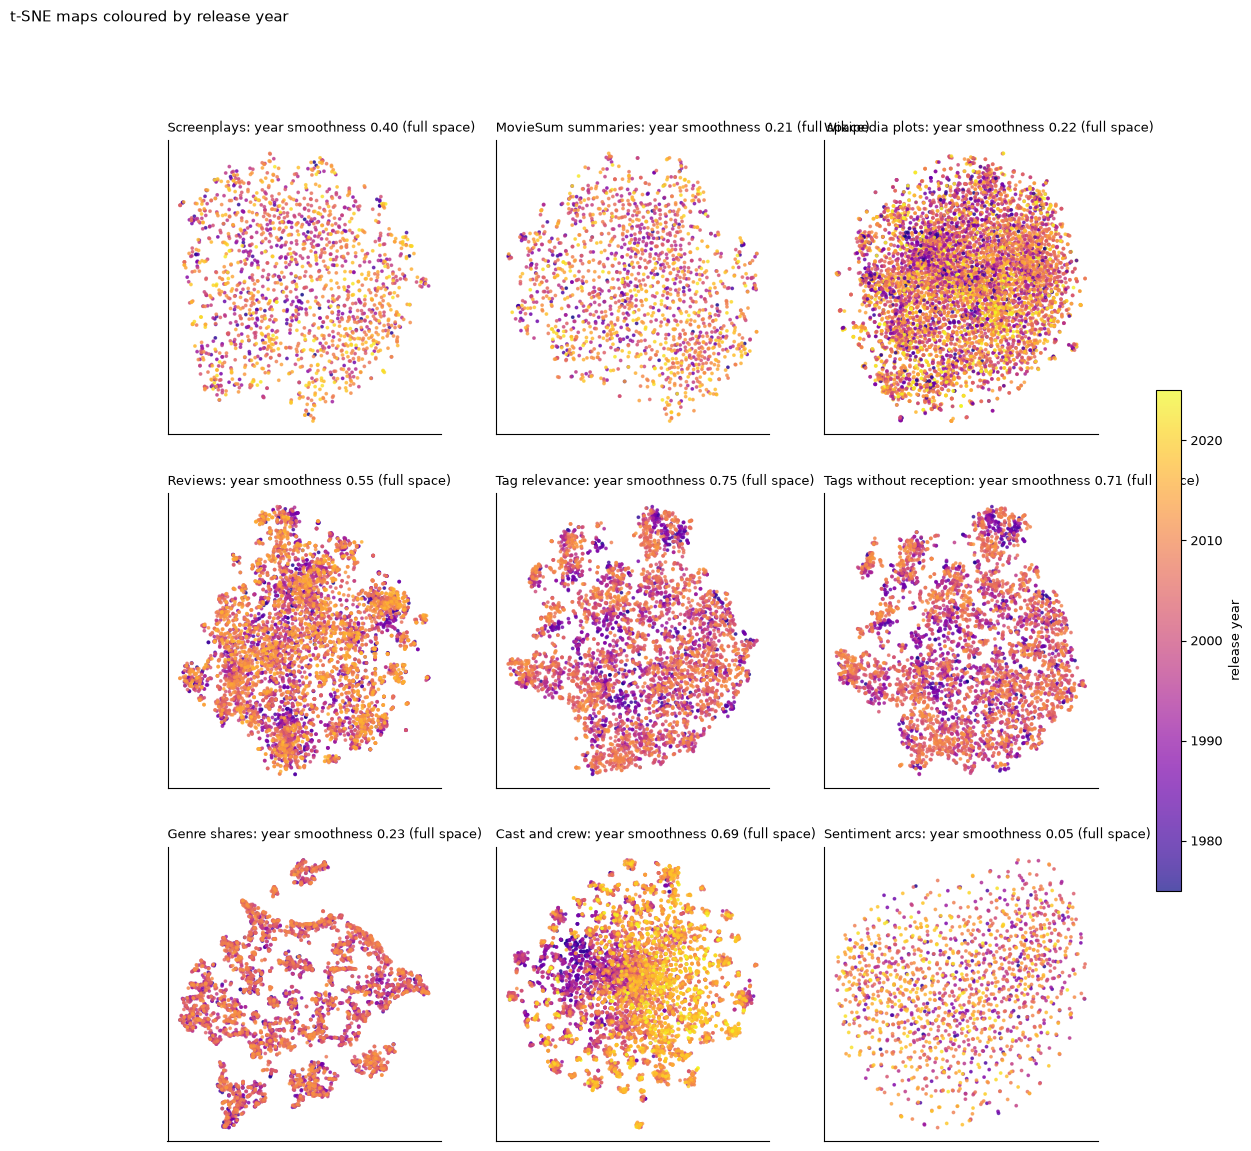

In [7]:
yr_rows = []
for name in NAMES:
    ids, V = S[name]
    yr = d.loc[ids].year.to_numpy()
    row = {"space": name, "full space": float(stats.spearmanr(yr, yr[knn(V)].mean(1)).statistic)}
    for method in ["PCA", "Isomap", "t-SNE", "UMAP"]:
        row[method] = float(stats.spearmanr(yr, yr[knn(saved_map(name, method))].mean(1)).statistic)
    yr_rows.append(row)
years = pd.DataFrame(yr_rows).set_index("space")
years.to_csv(OUT / "year_smoothness.csv")
print(years.round(3).to_string())

fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for ax, name in zip(axes.flat, NAMES):
    Y = saved_map(name, "t-SNE")
    sc = ax.scatter(Y[:, 0], Y[:, 1], c=d.loc[S[name][0]].year, cmap="plasma", s=3, vmin=1975, vmax=2025, alpha=0.7)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{name}: year smoothness {years.loc[name, 'full space']:.2f} (full space)", loc="left", fontsize=9)
fig.colorbar(sc, ax=axes, label="release year", shrink=0.5)
fig.suptitle("t-SNE maps coloured by release year", x=0.02, ha="left")
plt.show()

## 5. Neighbours by hand

The scores above compare spaces with themselves. Whether a space's nearest films are really alike needs a person.
The sheet below takes 10 well-known films (100,000+ votes) that every space covers, picked at random with a fixed
seed. For each film and space it lists its 3 nearest films in the full space and 1 random film from the same space,
shuffled, so the person judging can't tell which is which. The key is in a separate file.

**How to fill it in.** Open `analysis/embedding_maps/hand_check_sheet.csv` and, without opening the key, put 1 in
`similar` if the candidate is like the film in what the space describes (story for the text spaces, themes and tone
for tags and genres, the people for cast and crew, the emotional shape for arcs) and 0 if not. Leave a row empty if
you don't know the candidate. Then rerun the last cell, which scores neighbours against the random films.

In [8]:
common = set(d.index)
for ids, _ in S.values():
    common &= set(ids)
pool = sorted(t for t in common if d.loc[t, "votes"] >= 100_000)
rng = np.random.default_rng(20261116)
picks = list(rng.choice(pool, 10, replace=False))
print(f"{len(common):,} films are in all nine spaces, {len(pool):,} of them with 100,000+ votes; picked 10")

sheet_path, key_path = OUT / "hand_check_sheet.csv", OUT / "hand_check_key.csv"
if sheet_path.exists():
    print("sheet already exists; not overwriting it (delete it to draw a new one)")
else:
    rows = []
    for name in NAMES:
        ids, V = S[name]
        pos = pd.Series(np.arange(len(ids)), ids)
        nn = knn(V, 3)
        for t in picks:
            i = pos[t]
            cands = [(ids[j], 1) for j in nn[i]]
            others = np.setdiff1d(np.arange(len(ids)), np.append(nn[i], i))
            cands.append((ids[rng.choice(others)], 0))
            for c, is_nn in rng.permutation(np.array(cands, dtype=object)):
                rows.append({"space": name, "film": f"{d.loc[t, 'title']} ({d.loc[t, 'year']})",
                             "candidate": f"{d.loc[c, 'title']} ({d.loc[c, 'year']})", "neighbour": int(is_nn)})
    sheet = pd.DataFrame(rows).sample(frac=1, random_state=SEED).reset_index(drop=True)
    sheet.index.name = "row"
    sheet[["space", "film", "candidate"]].assign(similar="").to_csv(sheet_path)
    sheet[["neighbour"]].to_csv(key_path)
    print(f"wrote {len(sheet)} rows to {sheet_path} and the key to {key_path}")
print("films:", "; ".join(f"{d.loc[t, 'title']} ({d.loc[t, 'year']})" for t in picks))

1,113 films are in all nine spaces, 739 of them with 100,000+ votes; picked 10
sheet already exists; not overwriting it (delete it to draw a new one)
films: High Fidelity (2000); Nebraska (2013); American History X (1998); Tron: Legacy (2010); 30 Days of Night (2007); Disturbia (2007); The Cable Guy (1996); Mulholland Drive (2001); End of Days (1999); Ed Wood (1994)


In [9]:
sheet = pd.read_csv(sheet_path, index_col="row").join(pd.read_csv(key_path, index_col="row"))
done = sheet.dropna(subset=["similar"])
if done.empty:
    print("not judged yet: fill in the similar column of", sheet_path)
else:
    score = done.groupby(["space", "neighbour"]).similar.agg(["mean", "size"]).unstack("neighbour")
    score.columns = [f"{s} ({'neighbour' if n else 'random'})" for s, n in score.columns]
    print(f"{len(done)} of {len(sheet)} rows judged. Share judged similar, nearest films against random films:")
    print(score.round(2).to_string())

not judged yet: fill in the similar column of ../analysis/embedding_maps/hand_check_sheet.csv


## 6. What the checks show

**Stability.** Redrawn from a random start, t-SNE keeps 41 to 89% of each film's 10 nearest films on the seed-1 map,
depending on the space. UMAP with another seed keeps 25 to 72%. A different neighbourhood setting changes more (t-SNE
21 to 70%, UMAP 16 to 59%). Islands are less stable than neighbours. Only the two tag spaces get the same islands back
under a new seed (adjusted Rand 0.88 to 1.00). On the other spaces it is 0.08 to 0.74, and under a new setting
islands rarely survive (0.02 to 0.63). Sentiment arcs are the least stable on both scores, and Wikipedia plots keep
the fewest neighbours after them.
The islands on the text, cast and crew and arc maps shouldn't be described as groups of films.

**Agreement between spaces.** Two descriptions of the same story agree most: MovieSum summaries and Wikipedia plots
share 26% of each film's 10 nearest films (chance 0.6%). Screenplays share 16 to 17% with summaries and reviews, and
12% with Wikipedia plots and tags. Cast and crew shares 3 to 7% with every other space, far above chance (0.2 to
0.7%) but low. Who made a film says little about what it is about. Sentiment arcs share 0.8 to 1.4%, about chance
(0.65 to 0.9%), so the arc space has nothing in common with what the films are about. The two tag spaces share 86%,
as they should, since one is the other minus 106 columns.

**Clusters.** Cut into 10 clusters, the tag space explains 5.6% of the variation in ln(multiple) (shuffle 97.5th
percentile 0.4%) and 5.5% net of budget, year and genre. Tags without reception explain 3.9% (net 4.3%), genre shares
1.6% (net 1.0%) and cast and crew 1.4% (net 1.4%), all above their shuffles. Reviews and Wikipedia plots are above
chance raw (1.6% and 0.9%) but not net (0.4% and 0.2%, at their nulls). Screenplays, summaries and arcs are at or
below chance. So the text spaces' profit structure in the main notebook is local, between close neighbours, and
doesn't add up to groups of films that earn more. In the tag space without reception, the cluster named by animation
and family tags has the highest median multiple (2.88) and the one named by relationships and independent film the
lowest (1.20).

**Release year.** The spaces that hold the most profit structure also sort films most strongly by year: tag
relevance 0.752, tags without reception 0.715, cast and crew 0.689, reviews 0.548. Screenplays sit at 0.401, the
other texts and genre shares at 0.206 to 0.235, and sentiment arcs at 0.050. Year and year squared are in the net
multiple, so a smooth trend in profit over the years is already allowed for. But era can still carry what a linear
trend misses, such as one decade's hits and another's flops.

**Neighbours by hand.** `analysis/embedding_maps/hand_check_sheet.csv` has 360 rows (10 films, 9 spaces, 3
neighbours and 1 random film each), not yet judged. Until it is, nothing above shows that a space's nearest films
are alike in the way a viewer would mean.